# Experiment 4: Feature Scaling, Normalization and Standardization

Change the data in the marked cell, then Runtime -> Run all. Output appears below each cell.

In [1]:
# ------- Step 1: Import required libraries -------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import (MinMaxScaler, StandardScaler,
                                   RobustScaler, MaxAbsScaler)

pd.set_option('display.width', 88)
pd.set_option('display.max_columns', None)

In [2]:
# >>> CHANGE THIS DATA (your own records) and re-run: Runtime -> Run all <<<
# ------- Step 2: Create a sample dataset -------
data = {
    'Employee': ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J'],
    'Age': [22, 25, 47, 35, 46, 28, 31, 60, 24, 29],
    'Salary': [25000, 32000, 95000, 62000, 88000, 41000, 54000, 250000,
               30000, 45000],
    'Experience': [1, 2, 20, 10, 18, 4, 7, 35, 1, 5]
}
df = pd.DataFrame(data)
print(df)
cols = ['Age', 'Salary', 'Experience']

  Employee  Age  Salary  Experience
0        A   22   25000           1
1        B   25   32000           2
2        C   47   95000          20
3        D   35   62000          10
4        E   46   88000          18
5        F   28   41000           4
6        G   31   54000           7
7        H   60  250000          35
8        I   24   30000           1
9        J   29   45000           5



Summary statistics (before scaling):
         Age     Salary  Experience
count  10.00      10.00       10.00
mean   34.70   72200.00       10.30
std    12.38   66796.21       10.98
min    22.00   25000.00        1.00
25%    25.75   34250.00        2.50
50%    30.00   49500.00        6.00
75%    43.25   81500.00       16.00
max    60.00  250000.00       35.00


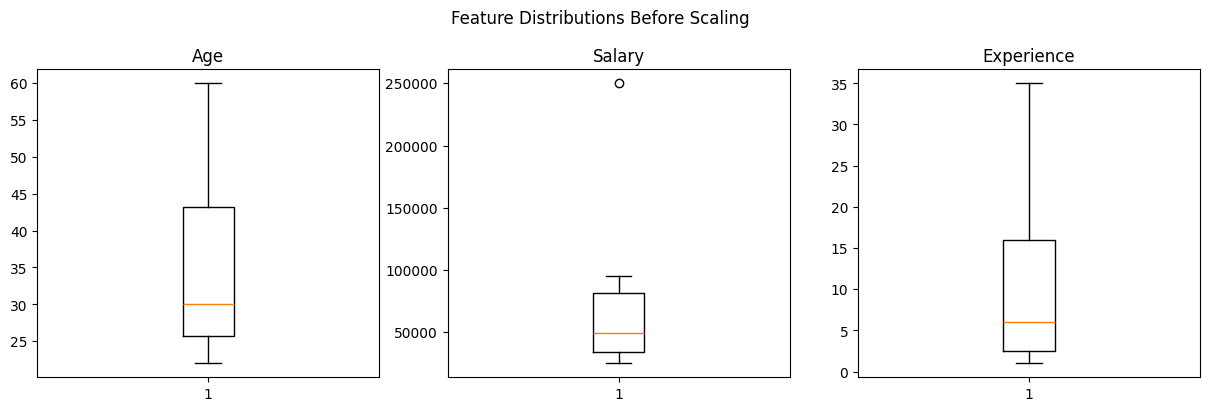

In [3]:
# ------- Step 3: Inspect the data before scaling -------
print("\nSummary statistics (before scaling):")
print(df[cols].describe().round(2))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].boxplot(df['Age']);        axs[0].set_title('Age')
axs[1].boxplot(df['Salary']);     axs[1].set_title('Salary')
axs[2].boxplot(df['Experience']); axs[2].set_title('Experience')
plt.suptitle("Feature Distributions Before Scaling", y=1.03)
plt.show()

In [4]:
# ------- Step 4: Min-Max normalization -------
minmax_scaler = MinMaxScaler()
df_minmax = df.copy()
df_minmax[cols] = minmax_scaler.fit_transform(df[cols])
print("\nMin-Max Scaled Data:\n", df_minmax.round(4))


Min-Max Scaled Data:
   Employee     Age  Salary  Experience
0        A  0.0000  0.0000      0.0000
1        B  0.0789  0.0311      0.0294
2        C  0.6579  0.3111      0.5588
3        D  0.3421  0.1644      0.2647
4        E  0.6316  0.2800      0.5000
5        F  0.1579  0.0711      0.0882
6        G  0.2368  0.1289      0.1765
7        H  1.0000  1.0000      1.0000
8        I  0.0526  0.0222      0.0000
9        J  0.1842  0.0889      0.1176


In [5]:
# ------- Step 5: Standardization (Z-score) -------
standard_scaler = StandardScaler()
df_standard = df.copy()
df_standard[cols] = standard_scaler.fit_transform(df[cols])
print("\nStandardized Data:\n", df_standard.round(4))
print("\nMean after scaling:\n", (df_standard[cols].mean().round(4) + 0.0))
print("\nStd after scaling (population, ddof=0):\n",
      df_standard[cols].std(ddof=0).round(4))


Standardized Data:
   Employee     Age  Salary  Experience
0        A -1.0811 -0.7449     -0.8932
1        B -0.8257 -0.6344     -0.7972
2        C  1.0470  0.3598      0.9316
3        D  0.0255 -0.1610     -0.0288
4        E  0.9619  0.2493      0.7395
5        F -0.5703 -0.4924     -0.6051
6        G -0.3150 -0.2872     -0.3169
7        H  2.1536  2.8058      2.3723
8        I -0.9108 -0.6659     -0.8932
9        J -0.4852 -0.4292     -0.5090

Mean after scaling:
 Age           0.0
Salary        0.0
Experience    0.0
dtype: float64

Std after scaling (population, ddof=0):
 Age           1.0
Salary        1.0
Experience    1.0
dtype: float64


In [6]:
# ------- Step 6: Robust scaling -------
robust_scaler = RobustScaler()
df_robust = df.copy()
df_robust[cols] = robust_scaler.fit_transform(df[cols])
print("\nRobust Scaled Data:\n", df_robust.round(4))


Robust Scaled Data:
   Employee     Age  Salary  Experience
0        A -0.4571 -0.5185     -0.3704
1        B -0.2857 -0.3704     -0.2963
2        C  0.9714  0.9630      1.0370
3        D  0.2857  0.2646      0.2963
4        E  0.9143  0.8148      0.8889
5        F -0.1143 -0.1799     -0.1481
6        G  0.0571  0.0952      0.0741
7        H  1.7143  4.2434      2.1481
8        I -0.3429 -0.4127     -0.3704
9        J -0.0571 -0.0952     -0.0741


In [7]:
# ------- Step 7: Max-Abs scaling -------
maxabs_scaler = MaxAbsScaler()
df_maxabs = df.copy()
df_maxabs[cols] = maxabs_scaler.fit_transform(df[cols])
print("\nMax-Abs Scaled Data:\n", df_maxabs.round(4))


Max-Abs Scaled Data:
   Employee     Age  Salary  Experience
0        A  0.3667   0.100      0.0286
1        B  0.4167   0.128      0.0571
2        C  0.7833   0.380      0.5714
3        D  0.5833   0.248      0.2857
4        E  0.7667   0.352      0.5143
5        F  0.4667   0.164      0.1143
6        G  0.5167   0.216      0.2000
7        H  1.0000   1.000      1.0000
8        I  0.4000   0.120      0.0286
9        J  0.4833   0.180      0.1429


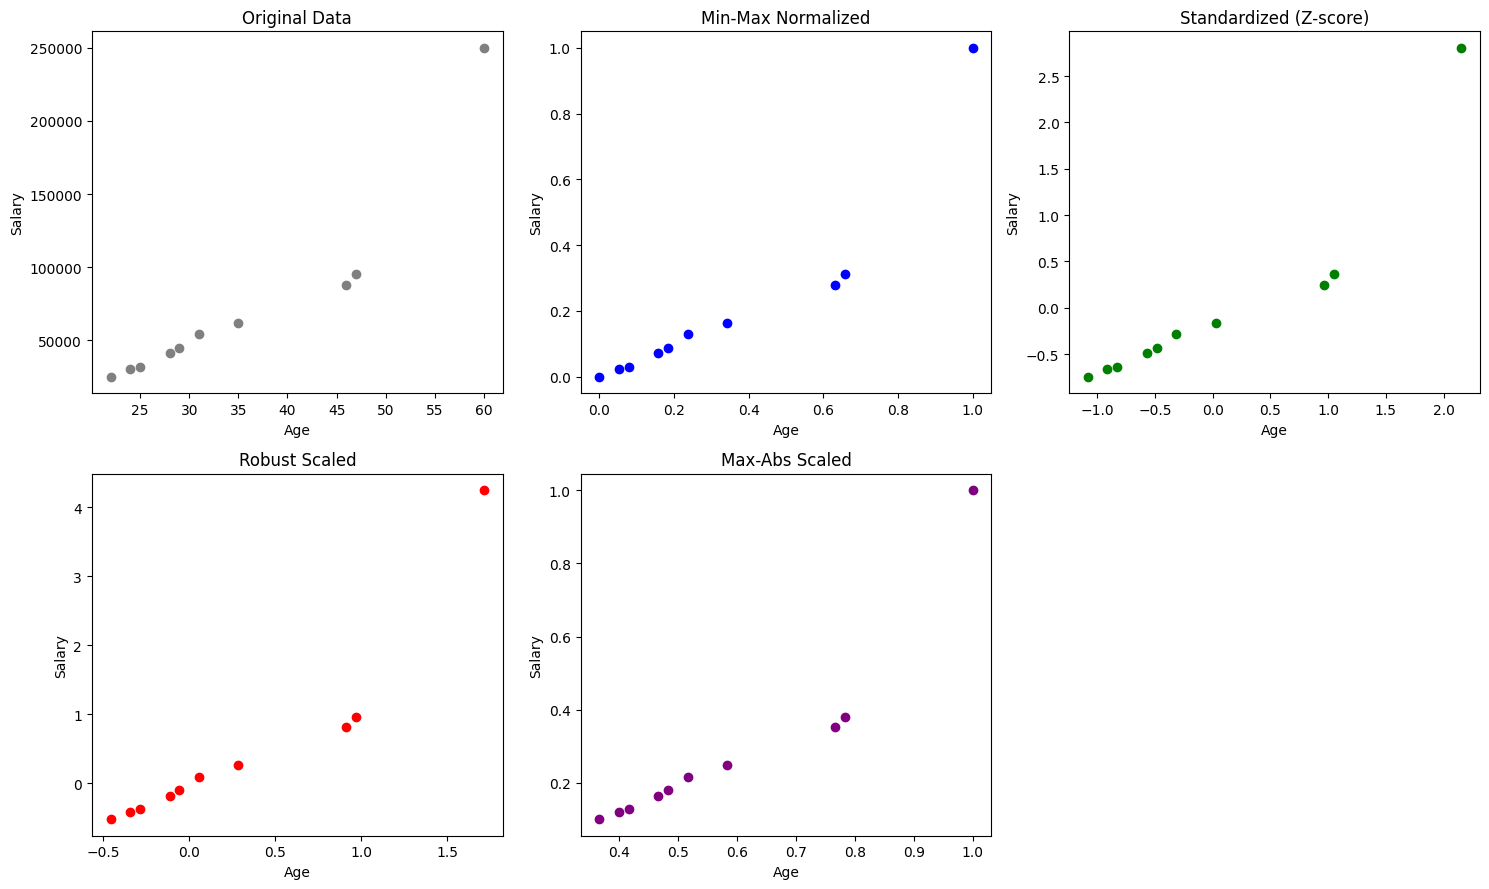

In [8]:
# ------- Step 8: Visual comparison of all techniques -------
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
plots = [
    (df,          "Original Data",         'gray'),
    (df_minmax,   "Min-Max Normalized",    'blue'),
    (df_standard, "Standardized (Z-score)", 'green'),
    (df_robust,   "Robust Scaled",         'red'),
    (df_maxabs,   "Max-Abs Scaled",        'purple'),
]
for ax, (d, title, colour) in zip(axs.flat, plots):
    ax.scatter(d['Age'], d['Salary'], color=colour)
    ax.set_title(title)
    ax.set_xlabel("Age")
    ax.set_ylabel("Salary")
axs[1, 2].axis('off')  # only five panels are needed
plt.tight_layout()
plt.show()

In [9]:
# ------- Step 9: Statistical summary of Salary across techniques -------
comparison = pd.DataFrame({
    'Original_Salary': df['Salary'],
    'MinMax_Salary': df_minmax['Salary'],
    'Standardized_Salary': df_standard['Salary'],
    'Robust_Salary': df_robust['Salary'],
    'MaxAbs_Salary': df_maxabs['Salary']
})
print("\nSalary under each technique:\n", comparison.round(4))
print("\nSummary statistics:\n", comparison.describe().round(4))


Salary under each technique:
    Original_Salary  MinMax_Salary  Standardized_Salary  Robust_Salary  MaxAbs_Salary
0            25000         0.0000              -0.7449        -0.5185          0.100
1            32000         0.0311              -0.6344        -0.3704          0.128
2            95000         0.3111               0.3598         0.9630          0.380
3            62000         0.1644              -0.1610         0.2646          0.248
4            88000         0.2800               0.2493         0.8148          0.352
5            41000         0.0711              -0.4924        -0.1799          0.164
6            54000         0.1289              -0.2872         0.0952          0.216
7           250000         1.0000               2.8058         4.2434          1.000
8            30000         0.0222              -0.6659        -0.4127          0.120
9            45000         0.0889              -0.4292        -0.0952          0.180

Summary statistics:
        Origi

In [10]:
# ------- Step 10: Manual implementation (without scikit-learn) -------
s = df['Salary']
df['Salary_MinMax_Manual'] = (s - s.min()) / (s.max() - s.min())
df['Salary_Standard_Manual'] = (s - s.mean()) / s.std(ddof=0)
print("\nManual vs scikit-learn check:")
print(df[['Salary', 'Salary_MinMax_Manual',
          'Salary_Standard_Manual']].round(4))
print("MinMax match:",
      np.allclose(df['Salary_MinMax_Manual'], df_minmax['Salary']))
print("Z-score match:",
      np.allclose(df['Salary_Standard_Manual'], df_standard['Salary']))


Manual vs scikit-learn check:
   Salary  Salary_MinMax_Manual  Salary_Standard_Manual
0   25000                0.0000                 -0.7449
1   32000                0.0311                 -0.6344
2   95000                0.3111                  0.3598
3   62000                0.1644                 -0.1610
4   88000                0.2800                  0.2493
5   41000                0.0711                 -0.4924
6   54000                0.1289                 -0.2872
7  250000                1.0000                  2.8058
8   30000                0.0222                 -0.6659
9   45000                0.0889                 -0.4292
MinMax match: True
Z-score match: True
